<a href="https://colab.research.google.com/github/Dan-KM/is-project-2/blob/main/app/model/colab/Irrigation_prediction_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Irrigation Action Prediction: Model Training

This notebook trains the classifier behind the irrigation decision support system.
Given a field's crop, soil and weather readings, it recommends one of four
irrigation actions: `No_Irrigation`, `Low`, `Medium` or `High`.

The saved pipeline (preprocessing + model) is served by a FastAPI service and
called by the farmer app. Every decision in this notebook therefore has to match
what the app can actually send: the same feature names, the same category
spellings and the same units.

**Structure**

1. Environment setup
2. Load data
3. Exploratory data analysis (EDA)
4. Train/test split
5. Feature selection
6. Preprocessing pipeline
7. Baseline models and cross-validation
8. Hyperparameter tuning
9. Final evaluation on the test set
10. Explainability
11. Model persistence and contract test

## 1. Environment setup

### 1.1 Detect the environment

The notebook can run in Google Colab or on a local machine, and each needs a
different set of dependencies. We first work out which environment we are in.

- `python-dotenv` reads a local `.env` file, so a local run can set
  `ENVIRONMENT` explicitly (for example `ENVIRONMENT=DEV`).
- In Colab there is no `.env` file, so Colab is detected automatically from
  the loaded modules.
- Anything unrecognised falls back to `DEV`, the safest default.

In [ ]:
%pip install -q python-dotenv

In [ ]:
import os
import sys
from dotenv import load_dotenv

# override=True: values in .env take precedence over existing OS variables
load_dotenv(override=True)

VALID_ENVIRONMENTS = {"PROD", "STAGING", "TESTING", "COLAB", "DEV"}


def resolve_environment():
    if os.environ.get("ENVIRONMENT"):
        return os.environ["ENVIRONMENT"].upper()
    if "google.colab" in sys.modules:
        return "COLAB"
    return "DEV"


ENV_SETUP = resolve_environment()
if ENV_SETUP not in VALID_ENVIRONMENTS:
    print(f"Warning: invalid ENVIRONMENT '{ENV_SETUP}'. Defaulting to 'DEV'.")
    ENV_SETUP = "DEV"

print(f"Environment: {ENV_SETUP}")

### 1.2 Install dependencies

Each environment has its own requirements file. A single lookup table replaces
the five near-identical `if/elif` branches of the earlier draft: adding an
environment now means adding one line, and there is no risk of the branches
drifting apart.

The constraints file pins exact versions for local runs. This matters because
the saved model must later be loaded by the FastAPI service with the **same**
scikit-learn version it was trained with.

In [ ]:
import subprocess

REQ_BASE = "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements"
CONSTRAINTS = ["-c", f"{REQ_BASE}/constraints.txt"]

REQUIREMENTS = {
    "PROD":    [f"{REQ_BASE}/prod.txt"],
    "STAGING": [f"{REQ_BASE}/dev.txt", *CONSTRAINTS],
    "TESTING": [f"{REQ_BASE}/dev.txt", *CONSTRAINTS],
    "COLAB":   [f"{REQ_BASE}/colab.txt"],
    "DEV":     [f"{REQ_BASE}/dev.txt", *CONSTRAINTS],
}

In [ ]:
def silent_pip_install(args):
    """Run pip quietly and print output only if it fails."""
    # sys.executable makes sure we install into the running kernel's environment
    cmd = [sys.executable, "-m", "pip", "install", *args]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stderr)


silent_pip_install(["-r", *REQUIREMENTS[ENV_SETUP]])
print(f"Dependencies installed for '{ENV_SETUP}'.")

### 1.3 Imports and display settings

Only the libraries used throughout the notebook are imported here. Modelling
libraries (scikit-learn estimators, SHAP, LIME) are imported in the step that
uses them, so each step can be read on its own.

Warnings are hidden to keep the outputs readable. While you are debugging a
cell, comment that line out so that nothing important is hidden.

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
warnings.filterwarnings("ignore")

### 1.4 Project constants

Values used in many cells are defined **once**, here. The earlier draft
redefined some of them later (`TARGET`, the class order, `numeric_cols`), which
let cells silently disagree depending on the order they were run in.

| Constant | Why it exists |
|---|---|
| `RANDOM_STATE` | Fixed seed, so the split, the CV folds and the models are reproducible. |
| `TARGET` | The column we predict. |
| `ID_COL` | `Field_ID` only identifies a field. It says nothing about irrigation need, so it is never used as a feature. |
| `CLASS_ORDER` | The natural order of the actions, from none to high. Plots and confusion matrices use it; alphabetical order would put `High` first. |
| `DATASET_URL`, `DATASET_PATH` | Where the data comes from, and where it is cached locally. |

In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET = "Irrigation_Action"
ID_COL = "Field_ID"
CLASS_ORDER = ["No_Irrigation", "Low", "Medium", "High"]

DATASET_URL = "https://raw.githubusercontent.com/Dan-KM/is-project-2/refs/heads/main/dataset/Irrigation_Scheduling_Dataset.csv"
DATASET_PATH = "./data/Irrigation_Scheduling_Dataset.csv"

## 2. Load data

The dataset is downloaded once from the project repository and cached in
`./data`, so re-running the cell does not download it again. Note that Colab
clears `./data` when the runtime restarts, so the first run of a new session
always downloads it.

In [ ]:
import urllib.request

if os.path.exists(DATASET_PATH):
    print("Dataset already exists locally.")
else:
    os.makedirs(os.path.dirname(DATASET_PATH), exist_ok=True)
    urllib.request.urlretrieve(DATASET_URL, DATASET_PATH)
    print("Dataset downloaded.")

df = pd.read_csv(DATASET_PATH, encoding="utf-8")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Field_ID                    7000 non-null   int64  
 1   Crop_Type                   7000 non-null   object 
 2   Growth_Stage                7000 non-null   object 
 3   Soil_Type                   7000 non-null   object 
 4   Day_of_Year                 7000 non-null   int64  
 5   Time_of_Day                 7000 non-null   int64  
 6   Soil_Moisture               6965 non-null   float64
 7   Soil_Temperature            6965 non-null   float64
 8   Soil_pH                     7000 non-null   float64
 9   Soil_EC                     7000 non-null   float64
 10  Ambient_Temperature         7000 non-null   float64
 11  Relative_Humidity           6965 non-null   float64
 12  Wind_Speed                  7000 non-null   float64
 13  Solar_Radiation             6965 

**Reading the output**

- 7,000 rows and 27 columns: `Field_ID`, 25 candidate predictors and the target.
- Six columns have 35 missing values each (0.5%): `Soil_Moisture`,
  `Soil_Temperature`, `Relative_Humidity`, `Solar_Radiation`, `Rainfall_24h` and
  `Historical_Soil_Moisture`. Every other column is complete.
- Three predictors are text (`Crop_Type`, `Growth_Stage`, `Soil_Type`), as is
  the target.

**Decision:** no rows are dropped. Missing values are filled in inside the
preprocessing pipeline (section 6). This matters because the app will also send
incomplete readings, and the pipeline must handle them in exactly the same way
at prediction time.

### 2.1 Target variable

The target is `Irrigation_Action`. The check below makes sure the dataset uses
exactly the four labels in `CLASS_ORDER`. If a label were misspelled (say,
`No irrigation`), the assertion stops the notebook here instead of letting a
fifth "class" leak into training.

In [ ]:
actual_classes = set(df[TARGET].unique())
assert actual_classes == set(CLASS_ORDER), f"Unexpected labels: {actual_classes ^ set(CLASS_ORDER)}"

n_predictors = df.shape[1] - 2  # everything except ID_COL and TARGET
print(f"Target: {TARGET}")
print(f"Classes (natural order): {CLASS_ORDER}")
print(f"Candidate predictors: {n_predictors}")

### 2.2 Data dictionary: units and ranges

A model learns from numbers, not units. Suppose it is trained on a feature
measured as a percentage, and the app later sends the same feature in litres.
The model then receives values far outside anything it has seen, and its
predictions become meaningless **without any error being raised**.

The dataset ([Kaggle: Irrigation Scheduling Dataset](https://www.kaggle.com/datasets/datcolabssnet/irrigation-scheduling-dataset))
does not document its units, and it appears to be synthetic. We therefore
infer each feature's unit from its observed range and compare it with what the
app sends.

In [ ]:
numeric_features = df.select_dtypes(include="number").columns.drop(ID_COL)

feature_ranges = pd.DataFrame({
    "min": df[numeric_features].min(),
    "q1": df[numeric_features].quantile(0.25),
    "median": df[numeric_features].median(),
    "q3": df[numeric_features].quantile(0.75),
    "max": df[numeric_features].max(),
    "missing": df[numeric_features].isna().sum(),
}).round(2)

feature_ranges

**Reading the output: inferred units compared with the app**

| Feature | Training range | Inferred dataset unit | App sends | Status |
|---|---|---|---|---|
| `Day_of_Year` | 1 – 365 | day of year | day of year (Nairobi) | OK |
| `Time_of_Day` | 0 – 23 | hour | hour (Nairobi) | OK |
| `Soil_Moisture` | 7.9 – 64.8 | % | % (farmer reading) | OK |
| `Soil_Temperature` | 12.0 – 39.7 | °C | °C | OK |
| `Soil_pH` | 5.0 – 8.2 | pH | pH | OK |
| `Soil_EC` | 0.25 – 2.78 | dS/m | dS/m | OK |
| `Ambient_Temperature` | 14.8 – 45.2 | °C | °C | OK |
| `Relative_Humidity` | 44.7 – 98.1 | % | % | OK |
| `Wind_Speed` | -0.02 – 15.1 | m/s | m/s | OK (a negative speed is noise) |
| `Solar_Radiation` | 49.7 – 950.2 | W/m², instantaneous | MJ/m²/day, daily total | **Mismatch** |
| `Rainfall_24h` | 0 – 81.4 | mm | mm | OK |
| `Rainfall_Forecast_24h` | 0 – 105.8 | mm | mm | OK |
| `Root_Zone_Depth` | 15 – 80 | cm | m (database) | **Convert** |
| `Leaf_Area_Index` | 0.35 – 6.14 | m²/m² | m²/m² | OK |
| `Crop_Coefficient` | 0.65 – 1.15 | Kc | Kc | OK |
| `Field_Slope` | 0.2 – 8.0 | % (assumed) | % | OK |
| `Water_Availability` | 10 – 100, most often 100 | % (how full) | litres remaining | **Mismatch** |
| `Previous_Irrigation_Amount` | 0.15 – 45 | mm of water depth | litres | **Convert** |
| `Days_Since_Last_Irrigation` | 0 – 14 | days | days, no upper limit | **Clip** |
| `Historical_Soil_Moisture` | 5.0 – 66.4 | % | % (7-day average) | OK |
| `Evaporation_Demand` | 2.0 – 97.7, median 45.7 | unknown index | ET₀ in mm/day | **Mismatch** |
| `Water_Stress_Index` | 24.9 – 100 | index | never sent | Dropped (section 5) |

Most features already match. Five need handling: four mismatches, plus one
range clip.

**Decision: train on the dataset's scale, convert in the app**

The model is trained on the data exactly as it is. The app converts its values
to the training scale before sending them. This keeps the notebook faithful to
the data, and it puts each conversion next to the source it depends on: the
database, the weather API or the water ledger.

| Feature | Conversion done by the app | Why |
|---|---|---|
| `Root_Zone_Depth` | metres × 100 → cm | The database stores metres; 0.15–0.80 m maps exactly onto the 15–80 cm range. |
| `Previous_Irrigation_Amount` | litres ÷ (field area in ha × 10,000) → mm | 1 litre spread over 1 m² is 1 mm of water, so this is an exact conversion, not an estimate. |
| `Water_Availability` | remaining budget ÷ budget at the last top-up × 100 → % | The 10–100 range, most often exactly 100, reads as "how full". A budget that has just been topped up is 100%. |
| `Solar_Radiation` | Open-Meteo *current* shortwave radiation (W/m²), clipped to 0 – 1,100, then mapped linearly onto 49.7 – 950.2: `49.7 + x / 1100 × (950.2 − 49.7)` | Same instantaneous unit as the dataset. The API's full range (0 at night, about 1,100 W/m² at a clear equatorial noon) is mapped range-to-range onto the training range, so night becomes the training minimum rather than a value the model has never seen. |
| `Evaporation_Demand` | **Not sent (dropped)** | The unit is undocumented, so any conversion from ET₀ would be a guess. Section 5 compares cross-validated scores with and without it, so the cost of dropping it is measured. |
| `Days_Since_Last_Irrigation` | values above 14 are sent as 14 | The model has never seen more than 14 days; "14 or more" is the safest reading. |

**Stated limitations (for the thesis)**

- The dataset is synthetic and undocumented, so the units above are inferred
  from value ranges, not confirmed.
- `Evaporation_Demand` is a strong predictor (section 3), but its unit cannot
  be matched to anything the app measures. It is dropped rather than fed a
  guessed conversion. Section 5 reports how much accuracy this costs.
- The `Solar_Radiation` mapping compresses daytime values slightly (for
  example, 600 W/m² is sent as about 541). This is accepted because the
  dataset's unit is itself only inferred, so matching ranges is as defensible
  as matching raw values, and it handles night consistently.
- `feature_ranges` is saved with the model (section 11). The API can then flag
  any value outside the training range instead of silently trusting it.

## 3. Exploratory data analysis (EDA)

EDA is about understanding the data before modelling it: how the classes are
balanced, how each feature is distributed, which features relate to the
target, and which features repeat each other. Each subsection ends with a
**conclusion** and the **decision** it leads to.

EDA uses the full dataset because it only *describes* the data. No feature is
kept or dropped here. Those decisions are made in section 5 on the training
set only, so the test set never influences the model.

### 3.1 Class balance

**Why:** the class balance decides two things: which metric is fair, and
whether we need resampling techniques such as SMOTE. If one class dominated,
a model could score well just by always predicting it.

In [ ]:
class_summary = pd.DataFrame({
    "count": df[TARGET].value_counts(),
    "proportion": df[TARGET].value_counts(normalize=True).round(3),
}).loc[CLASS_ORDER]

class_summary

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=TARGET, order=CLASS_ORDER, color="#4F6EA4")
plt.title("Class balance: Irrigation_Action")
plt.ylabel("Number of rows")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Conclusion:** the classes are perfectly balanced: 1,750 rows each (25%).

**Decisions:**
- **No resampling.** SMOTE, ADASYN and undersampling exist to fix imbalance,
  and there is none to fix. Synthetic rows would only add noise. The earlier
  draft used SMOTE everywhere; it is removed from section 7 onwards.
- **The bar to beat is 25%.** A model that guesses at random, or always
  predicts one class, scores about 25%. Section 7 measures this with a dummy
  model so every real model can be compared against it.
- **Macro-F1 is the main metric.** It weighs every class equally. On balanced
  data it behaves like accuracy, but it stays fair if real farm data turns out
  to be imbalanced.
- **The train/test split is stratified** (section 4), so both sets keep the
  25% balance.

### 3.2 Distribution of the numeric features

**Why:** skewed features (a long tail on one side) can dominate distance-based
and linear models, and features on very different scales need standardising.
This subsection decides which transforms the preprocessing pipeline needs
(section 6).

- **Skewness** near 0 means symmetric; above about 1 (or below -1) means a
  strong tail.
- **Kurtosis** (excess) above 0 means heavier tails than a normal
  distribution, so more extreme values.

In [ ]:
distribution_summary = pd.DataFrame({
    "mean": df[numeric_features].mean(),
    "std": df[numeric_features].std(),
    "skewness": df[numeric_features].skew(),
    "kurtosis": df[numeric_features].kurt(),
}).round(2)

distribution_summary.sort_values("skewness", key=abs, ascending=False)

**Conclusion:**
- `Rainfall_24h` and `Rainfall_Forecast_24h` are strongly right-skewed
  (skewness about 3.4, kurtosis about 12). Most days have little rain, and a
  few have a lot.
- `Wind_Speed` (1.3) and `Previous_Irrigation_Amount` (1.1) are moderately
  skewed.
- Every other feature is close to symmetric (|skewness| < 0.35).
- Scales differ widely: `Solar_Radiation` is in the hundreds, while
  `Soil_EC` is around 1.
- The most common value of `Water_Availability` is exactly its maximum (100),
  and the same holds for `Previous_Irrigation_Amount` (45). The data generator
  capped these values, which is another sign that the dataset is synthetic.

**Decisions (applied in section 6):**
- Rainfall gets a **Yeo-Johnson** transform to pull in the long tail.
  Yeo-Johnson is used instead of Box-Cox because rainfall contains zeros, and
  Box-Cox only accepts values above 0.
- The moderately skewed features are revisited in section 6, but only if they
  survive feature selection.
- Numeric features are **standardised**. Tree models do not need it, but
  logistic regression, KNN and SVM do, and we compare all of them.

### 3.3 Outliers

**Why:** extreme values can be data errors, which should be removed, or real
but rare events, which should be kept. We flag them using the **IQR rule**: a
value is an outlier if it lies more than 1.5 × IQR below the first quartile
or above the third quartile.

In [ ]:
q1 = df[numeric_features].quantile(0.25)
q3 = df[numeric_features].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outlier_mask = (df[numeric_features] < lower_fence) | (df[numeric_features] > upper_fence)
outlier_counts = outlier_mask.sum().sort_values(ascending=False)

outlier_counts[outlier_counts > 0].to_frame("outlier_count")

The plots below show the six most-flagged features. On the left is the
distribution with the fences marked. On the right is the same feature split
by irrigation action, which shows whether the extreme values belong to a
particular class.

In [ ]:
most_flagged = outlier_counts.index[:6]

fig, axes = plt.subplots(len(most_flagged), 2, figsize=(14, 3.5 * len(most_flagged)))

for row, col in enumerate(most_flagged):
    sns.histplot(df[col], kde=True, ax=axes[row, 0], color="#4F6EA4")
    axes[row, 0].axvline(lower_fence[col], color="red", linestyle="--")
    axes[row, 0].axvline(upper_fence[col], color="red", linestyle="--")
    axes[row, 0].set_title(f"{col}: distribution with IQR fences")

    sns.boxplot(data=df, x=TARGET, y=col, order=CLASS_ORDER, ax=axes[row, 1], color="#4F6EA4")
    axes[row, 1].set_title(f"{col} by irrigation action")
    axes[row, 1].set_xlabel("")

plt.tight_layout()
plt.show()

In [ ]:
# A physically impossible value: wind speed cannot be negative
negative_wind = df.loc[df["Wind_Speed"] < 0, "Wind_Speed"]
print(f"Negative wind speeds: {len(negative_wind)} rows, lowest = {negative_wind.min()}")

**Conclusion:**
- The flagged values are the **long tails of skewed features** (rainfall,
  wind, previous irrigation), not errors. A day with 80 mm of rain is rare but
  real, and it is exactly the case where the model should say `No_Irrigation`.
- `Crop_Coefficient` is flagged most often, but only because Kc takes a few
  fixed values (it comes from crop/stage tables). At least a quarter of the rows sit at exactly 0.90, so
  the IQR is narrow, and the legitimate value 0.65 falls outside it.
- The only impossible values are a few slightly negative wind speeds (a
  minimum of -0.02 m/s), which is tiny noise from the data generator.

**Decision:** **no rows are removed.** Removing real extremes would delete the
most informative cases. Tree models are not affected by extreme values, and
the transforms in section 6 handle the skew for the other models. The
negative wind speeds are too small to matter, and the app never sends a
negative value.

### 3.4 Relationship between each feature and the target

**Why:** this is the first indication of which features carry information
about the irrigation action. Three tests are used because each sees something
different:

| Test | Applies to | Detects |
|---|---|---|
| ANOVA F-test | numeric features | differences in class *means* (linear) |
| Cramér's V | categorical features | association between two categorical variables |
| Mutual information | all features | any dependence, including non-linear |

A feature that scores low on all three is a weak candidate for the model.

#### 3.4.1 ANOVA F-test (numeric features)

**The ANOVA F-statistic tests whether the mean of a numeric feature differs
across the four classes.** It compares the variance *between* the class
groups with the variance *within* each group.

- **F-statistic:** higher means the class means are more clearly separated.
  A value near 0 means no separation.
- **p-value:** the probability of an F this large if the feature had no real
  relationship with the target. Below 0.05 is taken as evidence of a genuine
  association.

The test cannot handle missing values, so they are temporarily filled with the
median. This is for the diagnostic only; the real imputation happens inside
the pipeline. The test only sees linear differences in means, so it is a
first screen, not a final decision.

In [ ]:
from sklearn.feature_selection import f_classif

numeric_filled = df[numeric_features].fillna(df[numeric_features].median())
f_stats, p_values = f_classif(numeric_filled, df[TARGET])

anova_summary = pd.DataFrame(
    {"F_statistic": f_stats, "p_value": p_values},
    index=numeric_features,
).sort_values("F_statistic", ascending=False)

anova_summary.round(4)

**Conclusion:**
- **Strong:** `Water_Stress_Index` (F ≈ 1,904), `Soil_Moisture` (865),
  `Historical_Soil_Moisture` (617), `Evaporation_Demand` (318), `Rainfall_24h`
  (238), `Solar_Radiation` (237) and `Rainfall_Forecast_24h` (139).
- **Moderate:** `Ambient_Temperature` (69), `Relative_Humidity` (42) and
  `Water_Availability` (18).
- **No significant difference (p > 0.05):** `Soil_Temperature`, `Wind_Speed`,
  `Time_of_Day`, `Day_of_Year`, `Field_Slope`, `Previous_Irrigation_Amount`,
  `Root_Zone_Depth`, `Soil_EC` and `Soil_pH`.

This agrees with irrigation practice: water need is driven by how wet the soil
is, how fast it dries (sun, heat) and how much rain falls or is coming.

#### 3.4.2 Cramér's V (categorical features)

Cramér's V measures the strength of association between a categorical feature
and the categorical target, based on the chi-square statistic. It ranges from
0 to 1 whatever the number of categories, so the features are comparable.

| Value | Association |
|---|---|
| 0.00 – 0.10 | negligible |
| 0.10 – 0.20 | weak |
| 0.20 – 0.40 | moderate |
| 0.40 and above | strong |

The version below uses **Bergsma's bias correction**, because the plain
formula slightly overstates association.

In [ ]:
def cramers_v(contingency_table):
    """Bias-corrected Cramer's V for a contingency table (counts)."""
    chi2_stat = stats.chi2_contingency(contingency_table)[0]
    n = contingency_table.sum()
    r, k = contingency_table.shape

    phi2 = chi2_stat / n
    phi2_corrected = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corrected = r - (r - 1) ** 2 / (n - 1)
    k_corrected = k - (k - 1) ** 2 / (n - 1)

    return np.sqrt(phi2_corrected / min(k_corrected - 1, r_corrected - 1))

In [ ]:
categorical_features = df.select_dtypes(exclude="number").columns.drop(TARGET).tolist()

cramers_v_summary = pd.Series(
    {col: cramers_v(pd.crosstab(df[col], df[TARGET]).values) for col in categorical_features},
    name="Cramers_V",
).sort_values(ascending=False).round(3)

cramers_v_summary.to_frame()

The chart below shows, for each category, the share of each irrigation action.
If a feature had no effect, every bar would look the same (25% each).

In [ ]:
fig, axes = plt.subplots(1, len(categorical_features), figsize=(16, 4.5))

for ax, col in zip(axes, categorical_features):
    shares = pd.crosstab(df[col], df[TARGET], normalize="index")[CLASS_ORDER]
    shares.plot(kind="bar", stacked=True, ax=ax, legend=False, colormap="viridis")
    ax.set_title(f"Irrigation action share by {col}")
    ax.set_ylabel("Proportion")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title=TARGET, loc="upper right")
plt.tight_layout()
plt.show()

**Conclusion:**
- **`Soil_Type` has a moderate association (V ≈ 0.22).** On sandy soil about
  half of the rows are `High` and very few are `No_Irrigation`. On clay it is
  the reverse. This matches soil physics: sand drains quickly and holds
  little water, while clay holds water for longer.
- **`Crop_Type` (0.03) and `Growth_Stage` (0.01) are negligible.** Their bars
  are almost identical across categories. Note that the earlier draft called
  0.22 "weak"; on the scale above it is moderate.

**Decision:** `Soil_Type` is a clear keep. `Crop_Type` and `Growth_Stage` look
uninformative in this dataset, but the app always sends them and agronomy
says they matter. Section 5 tests whether keeping them helps or hurts.

#### 3.4.3 Mutual information (all features)

Mutual information (MI) measures how much knowing a feature reduces
uncertainty about the target. Unlike ANOVA, it also detects non-linear
relationships, and it handles numeric and categorical features on one scale.
An MI of 0 means the feature tells us nothing about the target.

Categorical features are passed as integer codes and flagged as *discrete*,
so MI treats them as categories rather than as numbers.

In [ ]:
from sklearn.feature_selection import mutual_info_classif

mi_input = numeric_filled.copy()
for col in categorical_features:
    mi_input[col] = df[col].astype("category").cat.codes

is_discrete = [col in categorical_features for col in mi_input.columns]

mi_scores = pd.Series(
    mutual_info_classif(mi_input, df[TARGET], discrete_features=is_discrete, random_state=RANDOM_STATE),
    index=mi_input.columns,
).sort_values()

In [ ]:
mi_scores.plot(kind="barh", figsize=(8, 7), color="#4F6EA4")
plt.title("Mutual information with Irrigation_Action")
plt.xlabel("MI score (higher = more informative)")
plt.tight_layout()
plt.show()

**Conclusion:** MI agrees with ANOVA on the top of the ranking:
`Water_Stress_Index`, `Soil_Moisture`, `Historical_Soil_Moisture`, then
`Soil_Type`, `Evaporation_Demand`, `Solar_Radiation` and rainfall. No feature
that ANOVA called weak turns out to have a strong non-linear relationship.
`Field_Slope`, `Root_Zone_Depth`, `Previous_Irrigation_Amount`, `Soil_pH`,
`Time_of_Day` and `Day_of_Year` score about 0 on MI as well, so they are weak
on every test.

### 3.5 Feature profiles by irrigation action

**Why:** the tests above give one number per feature. The profiles show *how*
a feature changes from `No_Irrigation` to `High`, and how much the classes
overlap. That overlap tells us how hard the problem is.

Features are standardised (z-scores) so they can share one colour scale:
0 is the overall average, and ±1 is one standard deviation.

In [ ]:
z_scores = (df[numeric_features] - df[numeric_features].mean()) / df[numeric_features].std()
z_scores[TARGET] = df[TARGET]

class_profile = z_scores.groupby(TARGET)[numeric_features].mean().T[CLASS_ORDER]

plt.figure(figsize=(8, 7))
sns.heatmap(class_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Standardised feature means by irrigation action")
plt.xlabel("")
plt.show()

In [ ]:
n_plot_cols = 4
n_plot_rows = int(np.ceil(len(numeric_features) / n_plot_cols))
fig, axes = plt.subplots(n_plot_rows, n_plot_cols, figsize=(18, 3.8 * n_plot_rows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    sns.boxplot(data=df, x=TARGET, y=col, order=CLASS_ORDER, ax=ax, color="#4F6EA4")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

**Conclusion:**
- The strong features change **steadily** from `No_Irrigation` to `High`.
  Soil moisture falls from +0.65 to -0.76 standard deviations, while solar
  radiation rises from -0.42 to +0.43. Rainfall is highest for
  `No_Irrigation`. The labels follow the physics in the expected direction,
  which is a useful sanity check on the data.
- The box plots overlap heavily, especially between **neighbouring** classes
  (`Low` against `Medium`). The classes are not cleanly separable.

**What this means for the model:** expect most mistakes to fall between
neighbouring classes (predicting `Low` when the answer is `Medium`), and few
between the extremes (`No_Irrigation` against `High`). This also explains why
the earlier draft's models scored only about 0.51 macro-F1. Section 9 checks
whether the errors really fall between neighbours, which matters for the
farmer: a near miss is far less harmful than recommending heavy irrigation
when none is needed.

### 3.6 Correlation between numeric features

**Why:** two features that are strongly correlated carry largely the same
information. This matters for three reasons:
- logistic regression coefficients become unstable and harder to interpret;
- feature importance is split between the two features, so each looks weaker
  than it is;
- when one of a pair is dropped, the other can stand in for it, so dropping is
  cheap.

In [ ]:
plt.figure(figsize=(15, 12))
sns.heatmap(df[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

**Conclusion:** most features are uncorrelated (|r| < 0.05), as you would
expect from synthetic data. The notable pairs are:

| Pair | r | Meaning |
|---|---|---|
| `Solar_Radiation` – `Evaporation_Demand` | 0.95 | almost the same information |
| `Soil_Moisture` – `Historical_Soil_Moisture` | 0.85 | today's moisture tracks the recent average |
| `Leaf_Area_Index` – `Crop_Coefficient` | 0.85 | both describe crop size and stage |
| `Ambient_Temperature` – `Relative_Humidity` | -0.48 | hot air tends to be drier |
| `Water_Stress_Index` – `Soil_Moisture` | -0.76 | |
| `Water_Stress_Index` – `Historical_Soil_Moisture` | -0.65 | |
| `Water_Stress_Index` – `Ambient_Temperature` | 0.44 | |

**Decisions:**
- **Dropping `Evaporation_Demand` (section 2.2) should cost little.**
  `Solar_Radiation` carries almost the same information (r = 0.95). Section 5
  measures this.
- **Dropping `Water_Stress_Index` is less costly than its rank suggests.** It
  is largely a combination of soil moisture, temperature and rainfall, which
  the app *does* send, so the model can partly rebuild it.
- The other correlated pairs are kept for now. Section 5 tests whether one of
  each pair is redundant.

### 3.7 EDA summary

| Finding | Used in |
|---|---|
| Classes perfectly balanced, so no resampling, macro-F1 as the metric, and a 25% baseline | sections 4, 7 |
| Rainfall strongly skewed, so a Yeo-Johnson transform | section 6 |
| Scales differ widely, so standardise for linear and distance-based models | section 6 |
| Outliers are real extremes, so no rows are removed | section 6 |
| Strongest signals: soil moisture (today and recent), sun, rain, soil type | section 5 |
| Weak on every test: slope, root depth, previous irrigation, pH, EC, time, day, wind, soil temperature | section 5 |
| `Evaporation_Demand` ≈ `Solar_Radiation`, and `Water_Stress_Index` is largely rebuilt from sent features | section 5 |
| Neighbouring classes overlap, so expect near-miss errors | sections 7, 9 |

## Train/Test Split

The goal is to have test data and train data that reflect the same distribution of classes as the while dataset.

In [23]:
from sklearn.model_selection import train_test_split

feature_cols = [c for c in df.columns if c not in ["Field_ID", TARGET]]

X = df[feature_cols].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: 5600 rows
Test set: 1400 rows

Training class proportions:
Irrigation_Action
Medium           0.25
No_Irrigation    0.25
Low              0.25
High             0.25
Name: proportion, dtype: float64

Test class proportions:
Irrigation_Action
No_Irrigation    0.25
Medium           0.25
Low              0.25
High             0.25
Name: proportion, dtype: float64


## Feature selection

In [24]:
print(f"The starting features are {len(X_train.columns)}: {list(X_train.columns)}")

The starting features are 25: ['Crop_Type', 'Growth_Stage', 'Soil_Type', 'Day_of_Year', 'Time_of_Day', 'Soil_Moisture', 'Soil_Temperature', 'Soil_pH', 'Soil_EC', 'Ambient_Temperature', 'Relative_Humidity', 'Wind_Speed', 'Solar_Radiation', 'Rainfall_24h', 'Rainfall_Forecast_24h', 'Root_Zone_Depth', 'Leaf_Area_Index', 'Crop_Coefficient', 'Field_Slope', 'Water_Availability', 'Previous_Irrigation_Amount', 'Days_Since_Last_Irrigation', 'Historical_Soil_Moisture', 'Evaporation_Demand', 'Water_Stress_Index']


#### Chi-square test (categorical predictors)

The chi-square test requires non-negative integer-encoded categories and is sensitive to
low expected cell counts, so we apply it to label-encoded categorical columns.

- **Chi2 statistic:** Measures the strength of association between a feature
and the target. Higher values indicate a stronger relationship, meaning the
feature's distribution differs more between classes than would be expected by
chance.
- **p-value:** The probability of observing this association (or a stronger
one) if the feature were actually independent of the target. Low p-values
(typically **below 0.05**) suggest the association is unlikely to be due to random
noise, so the feature is probably informative.

**For feature selection:** We rank by `chi2_statistic`, **retain features with high
statistics and low p-values**, and discard features with high p-values (weak or
no real association).

In [25]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder

categorical_train = X_train[categorical_cols].copy()
categorical_train_encoded = categorical_train.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)))

chi2_stats, chi2_p_values = chi2(categorical_train_encoded, y_train)
chi2_summary = pd.DataFrame({
    "feature": categorical_cols,
    "chi2_statistic": chi2_stats,
    "p_value": chi2_p_values
}).sort_values("chi2_statistic", ascending=False)
chi2_summary.round(4)

,feature,chi2_statistic,p_value
2,Soil_Type,112.8676,0.0000
0,Crop_Type,15.8200,0.0012
1,Growth_Stage,6.2772,0.0989


### ANOVA F-test and Mutual Information (numeric predictors)

Mutual information captures non-linear dependence that the ANOVA F-test (a linear,
mean-difference test) can miss. Where the two disagree substantially on ranking, prefer
mutual information as a "sanity check", but do not discard a feature on the strength of
mutual information alone if it has a clear domain rationale.

| Situation                    | 	Interpretation                                                                        |
|------------------------------|---------------------------------------------------------------------------------------|
| High F-statistic AND high MI | Strong, likely linear signal; safe to retain                                          |
| Low F-statistic but high MI  | Non-linear relationship ANOVA missed; worth retaining, consider non-linear algorithms |
| High F-statistic but low MI  | Rare; check for a data leakage or coding issue                                        |
| Low on both                  | Weak candidate. Consider eliminating it.                                              |

In [26]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

numeric_train = X_train[numeric_cols].copy()
numeric_train_filled = numeric_train.fillna(numeric_train.median())

f_stats_train, p_values_train = f_classif(numeric_train_filled, y_train)
mi_scores = mutual_info_classif(numeric_train_filled, y_train, random_state=RANDOM_STATE)

numeric_selection_summary = pd.DataFrame({
    "feature": numeric_cols,
    "ANOVA_F": f_stats_train,
    "p_value": p_values_train,
    "mutual_info": mi_scores
}).sort_values("mutual_info", ascending=False)
numeric_selection_summary.round(4)

,feature,ANOVA_F,p_value,mutual_info
21,Water_Stress_Index,1548.0996,0.0000,0.3109
2,Soil_Moisture,691.8801,0.0000,0.1443
19,Historical_Soil_Moisture,497.4053,0.0000,0.1344
20,Evaporation_Demand,263.7314,0.0000,0.0710
9,Solar_Radiation,195.8217,0.0000,0.0423
10,Rainfall_24h,201.3156,0.0000,0.0357
11,Rainfall_Forecast_24h,103.0036,0.0000,0.0226
7,Relative_Humidity,35.6166,0.0000,0.0140
1,Time_of_Day,0.2090,0.8903,0.0089
15,Field_Slope,0.8561,0.4632,0.0065


In [27]:
numeric_selection_summary = numeric_selection_summary.copy()

numeric_selection_summary["ANOVA_rank"] = (
    numeric_selection_summary["ANOVA_F"]
    .rank(ascending=False, method="min")
)

numeric_selection_summary["MI_rank"] = (
    numeric_selection_summary["mutual_info"]
    .rank(ascending=False, method="min")
)

numeric_selection_summary["Average_rank"] = (
    numeric_selection_summary[["ANOVA_rank", "MI_rank"]]
    .mean(axis=1)
)

numeric_selection_summary = (
    numeric_selection_summary
    .sort_values("Average_rank")
    .reset_index(drop=True)
)

numeric_selection_summary.round(4)

,feature,ANOVA_F,p_value,mutual_info,ANOVA_rank,MI_rank,Average_rank
0,Water_Stress_Index,1548.0996,0.0000,0.3109,1.0,1.0,1.0
1,Soil_Moisture,691.8801,0.0000,0.1443,2.0,2.0,2.0
2,Historical_Soil_Moisture,497.4053,0.0000,0.1344,3.0,3.0,3.0
3,Evaporation_Demand,263.7314,0.0000,0.0710,4.0,4.0,4.0
4,Solar_Radiation,195.8217,0.0000,0.0423,6.0,5.0,5.5
5,Rainfall_24h,201.3156,0.0000,0.0357,5.0,6.0,5.5
6,Rainfall_Forecast_24h,103.0036,0.0000,0.0226,7.0,7.0,7.0
7,Relative_Humidity,35.6166,0.0000,0.0140,9.0,8.0,8.5
8,Ambient_Temperature,54.6137,0.0000,0.0061,8.0,12.0,10.0
9,Crop_Coefficient,3.8305,0.0094,0.0063,12.0,11.0,11.5


`Previous_Irrigation_Amount` has the lowest ANOVA_F and MI followed by `Water_Availability`

In [28]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Use identical data and folds for both models
feature_to_test = "Days_Since_Last_Irrigation"

X_with = X_train.copy()
X_without = X_train.drop(columns=[feature_to_test])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

def evaluate_model(X):
    numeric_cols = X.select_dtypes(include="number").columns
    categorical_cols = X.select_dtypes(
        include=["object", "category", "string"]
    ).columns

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    return cross_validate(
        model,
        X,
        y_train,
        cv=cv,
        scoring=["f1_macro", "balanced_accuracy"],
        n_jobs=-1
    )

results_with = evaluate_model(X_with)
results_without = evaluate_model(X_without)

In [29]:
comparison = pd.DataFrame({
    "With_feature": [
        results_with["test_f1_macro"].mean(),
        results_with["test_balanced_accuracy"].mean()
    ],
    "Without_feature": [
        results_without["test_f1_macro"].mean(),
        results_without["test_balanced_accuracy"].mean()
    ]
}, index=["Macro_F1", "Balanced_Accuracy"])

comparison["Difference"] = (
    comparison["With_feature"] - comparison["Without_feature"]
)

comparison.round(4)

,With_feature,Without_feature,Difference
Macro_F1,0.5110,0.5128,-0.0018
Balanced_Accuracy,0.5157,0.5184,-0.0027


### Recursive Feature Elimination (RFE)

RFE fits a model repeatedly, removing the weakest predictor(s) at each
iteration. We use a simple linear model as the estimator and rank all numeric
features (categorical features are handled separately via the encoding pipeline).

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

scaler_for_rfe = StandardScaler()
numeric_train_scaled = scaler_for_rfe.fit_transform(numeric_train_filled)

rfe_estimator = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)

# `StratifiedKFold` is used rather than plain `KFold` because the target is
# categorical. Stratification ensures each fold preserves the original class
# proportions, which matters for classification, particularly if any class is
# imbalanced.

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rfecv_selector = RFECV(
    estimator=rfe_estimator,
    step=1,
    cv=cv_strategy,
    scoring="accuracy",
    min_features_to_select=1
)
rfecv_selector.fit(numeric_train_scaled, y_train)

rfecv_ranking = pd.DataFrame({
    "feature": numeric_cols,
    "selected": rfecv_selector.support_,
    "rank": rfecv_selector.ranking_
}).sort_values("rank")

print(f"Optimal number of features: {rfecv_selector.n_features_}")
rfecv_ranking

Optimal number of features: 12


,feature,selected,rank
2,Soil_Moisture,True,1
7,Relative_Humidity,True,1
6,Ambient_Temperature,True,1
4,Soil_pH,True,1
13,Leaf_Area_Index,True,1
11,Rainfall_Forecast_24h,True,1
10,Rainfall_24h,True,1
9,Solar_Radiation,True,1
20,Evaporation_Demand,True,1
21,Water_Stress_Index,True,1


Here again `Previous_Irrigation_Amoount` was flagged.

Tree based feature importance

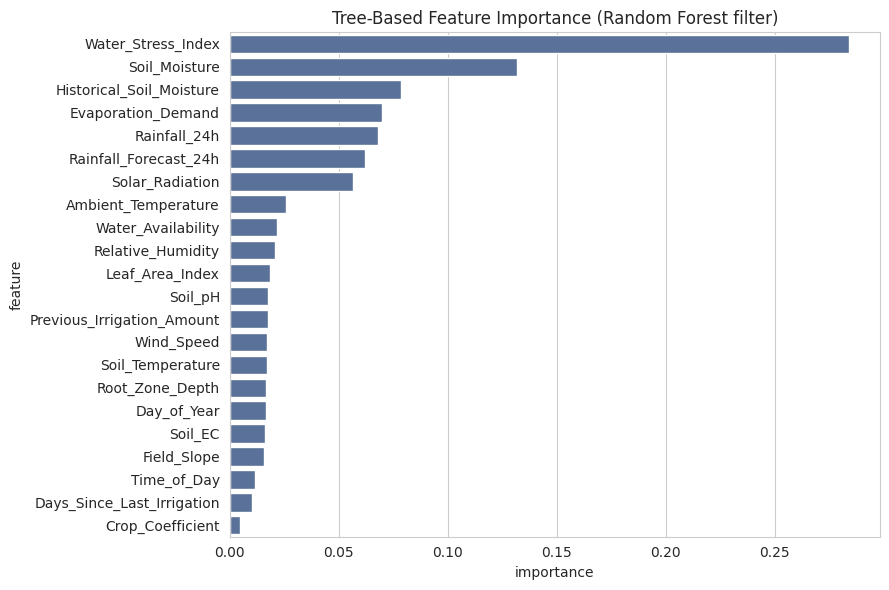

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf_filter = RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=300, max_depth=8)
rf_filter.fit(numeric_train_filled, y_train)

tree_importance = pd.DataFrame({
    "feature": numeric_cols,
    "importance": rf_filter.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=tree_importance, y="feature", x="importance", color="#4F6EA4")
plt.title("Tree-Based Feature Importance (Random Forest filter)")
plt.tight_layout()
plt.show()

In [32]:
# df = df.drop(columns=['Previous_Irrigation_Amount', 'Historical_Soil_Moisture', 'Days_Since_Last_Irrigation', 'Water_Availability', 'Growth_Stage'])

In [33]:
# print(f"The features remaining are {len(X_train.columns)}: {list(X_train.columns)}")

Data Preprocessing

In [34]:
cat_candidates = ["Crop_Type", "Growth_Stage", "Soil_Type", "Water_Availability", "Evaporation_Demand"]

for col in cat_candidates:
    # dtype tells you numeric vs text; unique values give you the exact spellings
    print(f"{col:22s} {str(X_train[col].dtype):8s} {sorted(X_train[col].dropna().unique())[:15]}")

print("\nMissing values per feature (train):")
print(X_train[FEATURES].isna().sum())

Crop_Type              object   ['Cotton', 'Groundnut', 'Maize', 'Rice', 'Soybean', 'Sugarcane', 'Tomato', 'Wheat']
Growth_Stage           object   ['Flowering', 'Fruiting', 'Maturity', 'Seedling', 'Vegetative']
Soil_Type              object   ['Clay', 'Loamy', 'Sandy', 'Silty']
Water_Availability     float64  [np.float64(10.0), np.float64(10.66), np.float64(10.87), np.float64(13.06), np.float64(13.92), np.float64(14.37), np.float64(15.8), np.float64(16.75), np.float64(16.89), np.float64(17.3), np.float64(17.74), np.float64(17.78), np.float64(18.33), np.float64(18.56), np.float64(18.75)]
Evaporation_Demand     float64  [np.float64(2.0), np.float64(2.88), np.float64(2.93), np.float64(3.6), np.float64(3.79), np.float64(4.31), np.float64(4.35), np.float64(4.74), np.float64(5.0), np.float64(5.04), np.float64(5.45), np.float64(6.31), np.float64(6.35), np.float64(6.79), np.float64(6.81)]

Missing values per feature (train):


NameError: name 'FEATURES' is not defined

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline   # NOT sklearn's: skips resampling at predict time
from imblearn.over_sampling import SMOTE

# =============================================================================
# 1. Column groups
# =============================================================================
nominal_cols = ["Crop_Type", "Soil_Type"]                     # no natural order -> one-hot

ordinal_cols = ["Growth_Stage"]                               # crop life cycle order -> ordinal

history_cols = ["Historical_Soil_Moisture",                   # structurally missing on a farmer's
                "Days_Since_Last_Irrigation",                 # first submission -> median + indicator
                "Previous_Irrigation_Amount"]

numeric_cols = ["Soil_Moisture", "Ambient_Temperature", "Evaporation_Demand", "Water_Availability"]

# One category list per ordinal column, in the same order as ordinal_cols
ordinal_orders = [
    ["Seedling", "Vegetative", "Flowering", "Fruiting", "Maturity"],   # Growth_Stage
]

skewed_cols = ["Rainfall_24h", "Rainfall_Forecast_24h"]

# =============================================================================
# 2. Guards: catch label typos or a forgotten feature before anything is fitted
# =============================================================================

for col, order in zip(ordinal_cols, ordinal_orders):
    unexpected = set(X_train[col].dropna().unique()) - set(order)
    assert not unexpected, f"{col} has labels not in your order list: {unexpected}"

all_assigned = nominal_cols + ordinal_cols + history_cols + numeric_cols + skewed_cols
assert sorted(all_assigned) == sorted(FEATURES), f"Mismatch: {set(FEATURES) ^ set(all_assigned)}"

# =============================================================================
# 3. Sub-pipelines (one per column group)
# =============================================================================
nominal_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),       # unseen crop at inference -> all zeros
])

ordinal_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=ordinal_orders,
                               handle_unknown="use_encoded_value",
                               unknown_value=-1)),            # unseen stage -> -1 instead of crashing
])

history_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),  # adds a 0/1 "was missing" column
    ("scaler", StandardScaler()),
])

skewed_pipeline = SkPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson")),  # standardize=True by default
])

numeric_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),            # Soil_Moisture & Rainfall_24h gaps
    ("scaler", StandardScaler()),                             # needed for LogReg/KNN/SVM comparisons
])

# =============================================================================
# 4. Combine into one preprocessor
# =============================================================================
preprocessor = ColumnTransformer(transformers=[
    ("nominal", nominal_pipeline, nominal_cols),
    ("ordinal", ordinal_pipeline, ordinal_cols),
    ("history", history_pipeline, history_cols),
    ("numeric", numeric_pipeline, numeric_cols),
], remainder="drop")                                          # anything not listed is excluded

# =============================================================================
# 5. Preview (sanity check only; the real fit happens inside CV below)
# =============================================================================
X_train_preview = preprocessor.fit_transform(X_train, y_train)
print(f"Shape after preprocessing: {X_train_preview.shape}")  # expect (n_rows, 23)
for name in preprocessor.get_feature_names_out():
    print("  ", name)

# =============================================================================
# 6. Full modelling pipeline: preprocess -> resample -> classify
# =============================================================================
rf_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),              # train folds only; skipped at predict()
    ("model", RandomForestClassifier(n_estimators=300, max_depth=8,
                                     random_state=RANDOM_STATE)),
])


Distribution transformation.

In [ ]:
# Box-Cox / Yeo-Johnson demonstration on skewed predictors
# Yeo-Johnson is used because Rainfall_24h and Rainfall_Forecast_24h contain zeros (Box-Cox requires > 0)
skewed_cols = ["Rainfall_24h", "Rainfall_Forecast_24h", "Previous_Irrigation_Amount"]

yeojohnson_demo = X_train[skewed_cols].copy()
yeojohnson_transformer = PowerTransformer(method="yeo-johnson", standardize=False)
yeojohnson_result = pd.DataFrame(
    yeojohnson_transformer.fit_transform(yeojohnson_demo),   # fit on training data only
    columns=skewed_cols
)

fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(12, 4.5 * len(skewed_cols)))

for i, col in enumerate(skewed_cols):
    sns.histplot(yeojohnson_demo[col], kde=True, ax=axes[i, 0], color="#4F6EA4")
    axes[i, 0].set_title(f"{col}: Before Yeo-Johnson")

    sns.histplot(yeojohnson_result[col], kde=True, ax=axes[i, 1], color="#4F6EA4")
    axes[i, 1].set_title(f"{col}: After Yeo-Johnson")

plt.tight_layout()
plt.show()

# Before/after skewness side by side
skewness_comparison = pd.DataFrame({
    "skewness_before": yeojohnson_demo.skew(),
    "skewness_after": yeojohnson_result.skew(),
    "lambda": yeojohnson_transformer.lambdas_,
}).round(2)
skewness_comparison

## Machine Learning Pipeline and Cross-Validation


In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=6),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=300, max_depth=8),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE, n_estimators=200, max_depth=3),
    "Support Vector Machine": SVC(probability=True, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB()
}

stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

for name, model in models.items():
    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", model)
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=stratified_kfold,
                              scoring="f1_macro", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:25s} F1-macro: {scores.mean():.4f}  (+/- {scores.std():.4f})")

In [ ]:
cv_results_df = pd.DataFrame(cv_results)
plt.figure(figsize=(11, 5))
sns.boxplot(data=cv_results_df, color="#4F6EA4")
plt.ylabel("Stratified Cross-Validated F1-macro")
plt.title("Stratified 5-Fold Cross-Validation: F1-macro by Model (with SMOTE)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import cross_validate

for name in ["Logistic Regression", "Random Forest", "Naive Bayes"]:
    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", models[name]),
    ])
    # return_train_score=True gives the score on the data each fold was trained on
    results = cross_validate(pipeline, X_train, y_train, cv=stratified_kfold,
                             scoring="f1_macro", return_train_score=True, n_jobs=-1)
    print(f"{name:20s} train: {results['train_score'].mean():.4f} | "
          f"validation: {results['test_score'].mean():.4f}")

confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Define class labels
class_labels = sorted(y_test.unique())

# 2. Fit the best Logistic Regression pipeline from your tuning/modeling steps
logreg_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOM_STATE))
])
logreg_pipeline.fit(X_train, y_train)
y_pred_logreg = logreg_pipeline.predict(X_test)

# 3. Fit the Random Forest pipeline
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

# 4. Plot the confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, y_pred) in zip(axes, [("Random Forest", y_pred_rf), ("Logistic Regression", y_pred_logreg)]):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.show()

Hyper param tuning

In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler

tuning_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("resampler", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

param_grid = {
    # "passthrough" = no resampling, which tests whether resampling helps at all
    "resampler": [
        SMOTE(random_state=RANDOM_STATE),
        ADASYN(random_state=RANDOM_STATE),
        RandomUnderSampler(random_state=RANDOM_STATE),
        "passthrough",
    ],
    "model__C": [0.01, 0.1, 1, 10, 100],          # smaller C = stronger regularization
    "model__class_weight": [None, "balanced"],    # alternative to resampling for imbalance
}

grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    cv=stratified_kfold,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)

print(f"Best tuned model: {grid_search.best_estimator_.named_steps['model']}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV F1-macro: {grid_search.best_score_:.4f}")

explainability

In [ ]:
# Fit a binary framing for clean odds-ratio interpretation: High risk vs. not High risk
y_train_binary = (y_train == "High").astype(int)
y_test_binary = (y_test == "High").astype(int)

logreg_binary_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logreg_binary_pipeline.fit(X_train, y_train_binary)

feature_names_out = preprocessor.get_feature_names_out()
log_odds = logreg_binary_pipeline.named_steps["model"].coef_[0]
odds_ratios = np.exp(log_odds)

odds_ratio_df = pd.DataFrame({
    "feature": feature_names_out,
    "log_odds_coefficient": log_odds,
    "odds_ratio": odds_ratios
}).sort_values("odds_ratio", ascending=False)

print("Interpretation: an odds ratio > 1 means the feature increases the odds of 'High' risk;")
print("an odds ratio < 1 means it decreases the odds, holding other features constant.")
odds_ratio_df

tree based feature importance

In [ ]:
final_feature_names = preprocessor.get_feature_names_out()
rf_importance = pd.DataFrame({
    "feature": final_feature_names,
    "importance": rf_pipeline.named_steps["model"].feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=rf_importance.head(15), y="feature", x="importance", color="#4F6EA4")
plt.title("Random Forest Feature Importance (Top 15)")
plt.tight_layout()
plt.show()

In [ ]:
import shap

# Fix: Assign the best estimator from the GridSearch to best_tuned_model
best_tuned_model = grid_search.best_estimator_

X_test_transformed = best_tuned_model.named_steps["preprocessor"].transform(X_test)
X_train_transformed = best_tuned_model.named_steps["preprocessor"].transform(X_train)
fitted_model = best_tuned_model.named_steps["model"]

print(f"Model classes in order: {fitted_model.classes_}")
print(f"Selected model type: {type(fitted_model).__name__}")
high_class_index = list(fitted_model.classes_).index("High")

# TreeExplainer only supports tree-based models (Random Forest, Gradient Boosting,
# Decision Tree). Since Stage 10's grid search can select ANY model family as "best",
# the explainer must adapt to whichever model type actually won.
# Non-tree models fall back to a model-agnostic explainer, which is slower
# (it queries the model many times), so it runs on a smaller sample.
tree_based_types = ("RandomForestClassifier", "GradientBoostingClassifier", "DecisionTreeClassifier")

if type(fitted_model).__name__ in tree_based_types:
    explainer = shap.TreeExplainer(fitted_model)
    shap_values = explainer.shap_values(X_test_transformed[:300])
    if isinstance(shap_values, list):
        shap_values_high_class = shap_values[high_class_index]
    else:
        shap_values_high_class = shap_values[:, :, high_class_index]
    plot_sample = X_test_transformed[:300]
else:
    background = shap.sample(X_train_transformed, 100, random_state=RANDOM_STATE)
    explainer = shap.Explainer(fitted_model.predict_proba, background)
    shap_explanation = explainer(X_test_transformed[:100])  # smaller subset -- this path is much slower
    shap_values_high_class = shap_explanation[..., high_class_index].values
    plot_sample = X_test_transformed[:100]

shap.summary_plot(shap_values_high_class, plot_sample,
                   feature_names=final_feature_names, show=False)
plt.title(f"SHAP Summary: Drivers of 'High' Risk Classification ({type(fitted_model).__name__})")
plt.tight_layout()
plt.show()

LIME

In [ ]:
%pip install lime

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=best_tuned_model.named_steps["preprocessor"].transform(X_train),
    feature_names=list(final_feature_names),
    class_names=list(best_tuned_model.named_steps["model"].classes_),
    mode="classification",
    random_state=RANDOM_STATE,
)

# Fix: Dynamically choose the first available index in the test set to avoid index mismatches
target_index = X_test.index[0]

if target_index not in X_test.index:
    raise ValueError(
        f"Applicant index {target_index} is not in the test set for this split "
        f"(it may have landed in the training set, or may not exist in the dataset at all)."
    )

position = X_test.index.get_loc(target_index)
sample_instance = X_test_transformed[position]

lime_explanation = lime_explainer.explain_instance(
    sample_instance,
    best_tuned_model.named_steps["model"].predict_proba,
    num_features=8,
)

print(f"Explaining prediction for test applicant index {target_index}")
print(f"Actual risk category: {y_test.loc[target_index]}")
for feature, weight in lime_explanation.as_list():
    print(f"  {feature:65s} {weight:+.4f}")

Model persistence

In [ ]:
import joblib
import os
from datetime import datetime

# Automatically picks the best tuned pipeline from GridSearchCV
final_pipeline = grid_search.best_estimator_

# (Optional) refit on the full training data to be explicit;
# GridSearchCV already does this when refit=True (the default)
final_pipeline.fit(X_train, y_train)

# Ensure the model folder exists
model_dir = "./model"
os.makedirs(model_dir, exist_ok=True)   # no error if it already exists

# Build the filename from the model name and a timestamp
# The timestamp prevents overwriting a previous run and keeps model versions traceable
model_name = final_pipeline.named_steps["model"].__class__.__name__
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_filename = f"{timestamp}_{model_name}_irrigation_action_classifier.joblib".lower()
model_path = os.path.normpath(os.path.join(model_dir, model_filename))

joblib.dump(final_pipeline, model_path)
print("Selected model:", model_name)
print(f"✅ Best pipeline (preprocessing + model) saved to: {model_path}")

In [ ]:
import pandas as pd

# Load using the path from Step 1. Hardcoding a filename breaks once the timestamp changes.
loaded_pipeline = joblib.load(model_path)

# One farmer submission, using the same 12 features the model was trained on
# Category spellings must match the dataset exactly (check with df_cols_keep[col].unique())
new_submission = pd.DataFrame([{
    "Crop_Type": "rice",
    "Growth_Stage": "Vegetative",
    "Soil_Type": "Loamy",
    "Soil_Moisture": 12.5,                 # farmer input
    "Water_Availability": 10,              # farmer input
    "Ambient_Temperature": 28.4,           # weather API
    "Rainfall_24h": 0.0,                   # weather API
    "Rainfall_Forecast_24h": 1.2,          # weather API
    "Evaporation_Demand": 5.1,             # weather API
    "Previous_Irrigation_Amount": 15.0,    # system irrigation log
    "Days_Since_Last_Irrigation": 4,       # system irrigation log
    "Historical_Soil_Moisture": 30.0,      # previous submission
}])

predicted_action = loaded_pipeline.predict(new_submission)[0]
predicted_proba = loaded_pipeline.predict_proba(new_submission)[0]

print(f"Recommended irrigation action: {predicted_action}")
print("\nClass probabilities:")
for cls, proba in zip(loaded_pipeline.classes_, predicted_proba):
    print(f"  {cls}: {proba:.3f}")

# One input row should produce exactly one prediction
print(f"\nInput rows: {len(new_submission)} -> predictions: {len(loaded_pipeline.predict(new_submission))}")

In [ ]:
import requests
import pandas as pd

# Farm location: replace with the farmer's coordinates (Nairobi used as an example)
LAT, LON = -1.2921, 36.8219

def fetch_weather_features(lat, lon):
    """Return the 4 weather features the model expects, from Open-Meteo."""
    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m",                               # Ambient_Temperature
        "hourly": "precipitation,et0_fao_evapotranspiration",      # rainfall + ET0
        "past_hours": 24,          # window ends at the current hour
        "forecast_hours": 24,      # window starts after the current hour
        "timezone": "auto",        # local time, so 'now' and the hourly times line up
    }
    resp = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=10)
    resp.raise_for_status()        # stop on HTTP errors (e.g. a bad parameter returns 400)
    data = resp.json()

    # Hourly arrays -> DataFrame indexed by timestamp
    hourly = pd.DataFrame(data["hourly"])
    hourly["time"] = pd.to_datetime(hourly["time"])
    now = pd.to_datetime(data["current"]["time"])

    past = hourly[hourly["time"] <= now]     # previous 24 hours
    future = hourly[hourly["time"] > now]    # next 24 hours

    return {
        "Ambient_Temperature": data["current"]["temperature_2m"],
        "Rainfall_24h": round(past["precipitation"].sum(), 2),
        "Rainfall_Forecast_24h": round(future["precipitation"].sum(), 2),
        "Evaporation_Demand": round(future["et0_fao_evapotranspiration"].sum(), 2),  # mm over the next 24h
    }

weather = fetch_weather_features(LAT, LON)
print("Weather features:", weather)

# Farmer inputs + system records, merged with live weather
new_submission = pd.DataFrame([{
    "Crop_Type": "rice",
    "Growth_Stage": "Vegetative",
    "Soil_Type": "sandy",
    "Soil_Moisture": 22.5,                 # farmer input
    "Water_Availability": 60.0,            # farmer input
    "Previous_Irrigation_Amount": 15.0,    # system irrigation log
    "Days_Since_Last_Irrigation": 4,       # system irrigation log
    "Historical_Soil_Moisture": 30.0,      # previous submission
    **weather,                             # the 4 Open-Meteo features
}])[FEATURES]                              # reorder columns to match training

# Flag weather values that fall outside what the model saw in training
for col in weather:
    lo, hi = df[col].min(), df[col].max()
    if not lo <= weather[col] <= hi:
        print(f"⚠️ {col}={weather[col]} is outside the training range [{lo}, {hi}]")

predicted_action = loaded_pipeline.predict(new_submission)[0]
predicted_proba = loaded_pipeline.predict_proba(new_submission)[0]

print(f"\nRecommended irrigation action: {predicted_action}")
for cls, proba in zip(loaded_pipeline.classes_, predicted_proba):
    print(f"  {cls}: {proba:.3f}")

weather api python testing

In [ ]:
!pip install openmeteo-requests
!pip install requests-cache retry-requests numpy pandas

In [ ]:
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://api.open-meteo.com/v1/forecast"
params = {
	"latitude": -1.2833,
	"longitude": 36.8167,
	"daily": "rain_sum",
	"hourly": ["temperature_2m", "rain", "soil_temperature_0cm", "soil_temperature_6cm", "soil_temperature_18cm", "soil_temperature_54cm", "soil_moisture_0_to_1cm", "soil_moisture_1_to_3cm", "soil_moisture_3_to_9cm", "soil_moisture_9_to_27cm", "soil_moisture_27_to_81cm", "wind_speed_10m", "weather_code", "evapotranspiration", "temperature_80m", "direct_radiation", "direct_radiation_instant"],
	"current": ["temperature_2m", "precipitation", "rain"],
	"timezone": "auto",
	"past_days": 1,
	"forecast_days": 1,
}
responses = openmeteo.weather_api(url, params = params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone: {response.Timezone()}{response.TimezoneAbbreviation()}")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process current data. The order of variables needs to be the same as requested.
current = response.Current()
current_temperature_2m = current.Variables(0).Value()
current_precipitation = current.Variables(1).Value()
current_rain = current.Variables(2).Value()

print(f"\nCurrent time: {current.Time()}")
print(f"Current temperature_2m: {current_temperature_2m}")
print(f"Current precipitation: {current_precipitation}")
print(f"Current rain: {current_rain}")

# Process hourly data. The order of variables needs to be the same as requested.
hourly = response.Hourly()
hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
hourly_rain = hourly.Variables(1).ValuesAsNumpy()
hourly_soil_temperature_0cm = hourly.Variables(2).ValuesAsNumpy()
hourly_soil_temperature_6cm = hourly.Variables(3).ValuesAsNumpy()
hourly_soil_temperature_18cm = hourly.Variables(4).ValuesAsNumpy()
hourly_soil_temperature_54cm = hourly.Variables(5).ValuesAsNumpy()
hourly_soil_moisture_0_to_1cm = hourly.Variables(6).ValuesAsNumpy()
hourly_soil_moisture_1_to_3cm = hourly.Variables(7).ValuesAsNumpy()
hourly_soil_moisture_3_to_9cm = hourly.Variables(8).ValuesAsNumpy()
hourly_soil_moisture_9_to_27cm = hourly.Variables(9).ValuesAsNumpy()
hourly_soil_moisture_27_to_81cm = hourly.Variables(10).ValuesAsNumpy()
hourly_wind_speed_10m = hourly.Variables(11).ValuesAsNumpy()
hourly_weather_code = hourly.Variables(12).ValuesAsNumpy()
hourly_evapotranspiration = hourly.Variables(13).ValuesAsNumpy()
hourly_temperature_80m = hourly.Variables(14).ValuesAsNumpy()
hourly_direct_radiation = hourly.Variables(15).ValuesAsNumpy()
hourly_direct_radiation_instant = hourly.Variables(16).ValuesAsNumpy()

hourly_data = {
	"date": pd.date_range(
		start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = hourly.Interval()),
		inclusive = "left"
	).tz_convert(response.Timezone().decode())
}

hourly_data["temperature_2m"] = hourly_temperature_2m
hourly_data["rain"] = hourly_rain
hourly_data["soil_temperature_0cm"] = hourly_soil_temperature_0cm
hourly_data["soil_temperature_6cm"] = hourly_soil_temperature_6cm
hourly_data["soil_temperature_18cm"] = hourly_soil_temperature_18cm
hourly_data["soil_temperature_54cm"] = hourly_soil_temperature_54cm
hourly_data["soil_moisture_0_to_1cm"] = hourly_soil_moisture_0_to_1cm
hourly_data["soil_moisture_1_to_3cm"] = hourly_soil_moisture_1_to_3cm
hourly_data["soil_moisture_3_to_9cm"] = hourly_soil_moisture_3_to_9cm
hourly_data["soil_moisture_9_to_27cm"] = hourly_soil_moisture_9_to_27cm
hourly_data["soil_moisture_27_to_81cm"] = hourly_soil_moisture_27_to_81cm
hourly_data["wind_speed_10m"] = hourly_wind_speed_10m
hourly_data["weather_code"] = hourly_weather_code
hourly_data["evapotranspiration"] = hourly_evapotranspiration
hourly_data["temperature_80m"] = hourly_temperature_80m
hourly_data["direct_radiation"] = hourly_direct_radiation
hourly_data["direct_radiation_instant"] = hourly_direct_radiation_instant

hourly_dataframe = pd.DataFrame(data = hourly_data)
print("\nHourly data\n", hourly_dataframe)

# Process daily data. The order of variables needs to be the same as requested.
daily = response.Daily()
daily_rain_sum = daily.Variables(0).ValuesAsNumpy()

daily_data = {
	"date": pd.date_range(
		start = pd.to_datetime(daily.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(daily.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = daily.Interval()),
		inclusive = "left"
	).tz_convert(response.Timezone().decode())
}

daily_data["rain_sum"] = daily_rain_sum

daily_dataframe = pd.DataFrame(data = daily_data)
print("\nDaily data\n", daily_dataframe)


In [ ]:
import pandas as pd

# Display the hourly weather data as a formatted pandas DataFrame
print("=== Hourly Weather Data DataFrame ===")
display(hourly_dataframe.head(10))

# Display the daily weather data as a formatted pandas DataFrame
print("\n=== Daily Weather Data DataFrame ===")
display(daily_dataframe)

In [ ]:
import pandas as pd
from google.colab import files

# Define the filename
excel_filename = 'weather_data_export.xlsx'

# Make copies to avoid modifying original dataframes
hourly_export = hourly_dataframe.copy()
daily_export = daily_dataframe.copy()

# Strip timezone awareness so Excel can save them cleanly
hourly_export['date'] = hourly_export['date'].dt.tz_localize(None)
daily_export['date'] = daily_export['date'].dt.tz_localize(None)

# Write both hourly and daily dataframes into a single Excel file on separate sheets
with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    hourly_export.to_excel(writer, sheet_name='Hourly Weather', index=False)
    daily_export.to_excel(writer, sheet_name='Daily Weather', index=False)

print(f'✅ Excel file created successfully: {excel_filename}')

# Trigger the download helper in Google Colab
files.download(excel_filename)